# 07.5 · Forecasting with machine learning

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/07-forecasting/05-ml-forecasting/lesson.ipynb)

Read the [README](README.md) and build the 5-row table by hand first. This notebook builds the same table in Pandas, turns ShopWave's daily revenue into a supervised-learning table, trains gradient boosting, compares **direct** and **recursive** multi-step forecasting, shows a trap that catches many people, and puts the result through the same backtest as 07.2–07.4.

## 1. A series becomes a table, by hand

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

toy = pd.Series([30, 32, 28, 40, 25, 0, 18, 31, 33, 29, 42, 26],     # £k, starting on a Monday
                index=pd.date_range("2011-11-07", periods=12, freq="D"))

table = pd.DataFrame({
    "day": toy.index.strftime("%a %d"),
    "lag_1": toy.shift(1),                         # yesterday
    "lag_7": toy.shift(7),                         # same weekday last week
    "mean_3": toy.shift(1).rolling(3).mean().round(2),   # average of the 3 days before
    "dow": toy.index.day_of_week,                  # 0 = Monday
    "y": toy,
})
table.iloc[7:]

,day,lag_1,lag_7,mean_3,dow,y
2011-11-14,Mon 14,18.0,30.0,14.33,0,31
2011-11-15,Tue 15,31.0,32.0,16.33,1,33
2011-11-16,Wed 16,33.0,28.0,27.33,2,29
2011-11-17,Thu 17,29.0,40.0,31.00,3,42
2011-11-18,Fri 18,42.0,25.0,34.67,4,26


Every row is one day; every column is something known *before* that day; `y` is what we want to predict. Once a series looks like this, any regression model from Modules 02–05 can learn from it. Note the `shift(1)` before `rolling`: the rolling mean must end *yesterday*, or today's value would leak into its own feature.

## 2. ShopWave's daily table

In [2]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

# The two sheets overlap: "Year 2009-2010" runs to 9 Dec 2010, "Year 2010-2011" starts 1 Dec 2010.
older = load_retail("Year 2009-2010")
newer = load_retail("Year 2010-2011")
raw = pd.concat([older[older["InvoiceDate"] < "2010-12-01"], newer], ignore_index=True)

def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df[~df["Invoice"].astype(str).str.startswith("C")]
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
    return out.assign(Revenue=out["Quantity"] * out["Price"])

sales = clean_retail(raw)
sales = sales[sales["Quantity"] < 70_000]          # two one-off orders, both cancelled the same day
END = pd.Timestamp("2011-12-04")                    # last complete week (Mon 28 Nov - Sun 4 Dec)
sales = sales[sales["InvoiceDate"] < END + pd.Timedelta(days=1)]

rev = sales.set_index("InvoiceDate")["Revenue"]
daily = rev.resample("D").sum()                     # every calendar day, 0 when closed
weekly = rev.resample("W").sum()                    # weeks end on Sunday
monthly = rev.resample("ME").sum()                  # month-end dates
monthly = monthly[monthly.index <= "2011-11-30"]    # December 2011 has only 4 days: drop it
print(f"{len(sales):,} order lines, {daily.index[0].date()} to {daily.index[-1].date()}")
print(f"{len(daily)} days, {len(weekly)} weeks, {len(monthly)} months")

H = 5                                                   # forecast 5 weeks ahead
ORIGINS = pd.date_range("2011-04-03", periods=8, freq="4W-SUN")      # 3 Apr ... 16 Oct 2011

def backtest(forecast_fn, series=None, origins=ORIGINS, h=H):
    """Rolling-origin backtest: at each origin, fit on the past, forecast h weeks, score MAE."""
    series = weekly if series is None else series
    rows = []
    for origin in origins:
        train = series[series.index <= origin]
        test = series[series.index > origin].iloc[:h]
        pred = np.asarray(forecast_fn(train, len(test)))
        rows.append({"origin": origin.date(), "MAE": np.abs(test.values - pred).mean()})
    return pd.DataFrame(rows)

def naive(train, h):          return np.repeat(train.iloc[-1], h)
def mean_fc(train, h):        return np.repeat(train.mean(), h)
def seasonal_naive(train, h): return train.iloc[-52:-52 + h].values
def drift(train, h):
    slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
    return train.iloc[-1] + slope * np.arange(1, h + 1)

from statsmodels.tsa.holtwinters import ExponentialSmoothing

def holt_winters(train, h):
    """Additive Holt-Winters, seeded with the first year as the starting seasonal pattern."""
    first = train.iloc[:52]
    model = ExponentialSmoothing(
        train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=52,
        initialization_method="known", initial_level=first.mean(), initial_trend=0.0,
        initial_seasonal=(first - first.mean()).values).fit()
    return model.forecast(h).values

import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX

def sarima(train, h):
    """SARIMA(1,0,1)(0,1,0,52) with a constant: last year's week, corrected by recent errors."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # statsmodels start-value notices, not errors
        model = SARIMAX(train, order=(1, 0, 1), seasonal_order=(0, 1, 0, 52), trend="c").fit(disp=False)
    return model.forecast(h).values

from sklearn.ensemble import HistGradientBoostingRegressor

def daily_table(d):
    """Turn the daily series into a table. Every lag is >= 35 days, so 5 weeks ahead is honest."""
    t = pd.DataFrame({"y": d})
    t["lag_35"] = d.shift(35)
    t["mean_28_lag_35"] = d.shift(35).rolling(28).mean()
    t["dow"] = d.index.day_of_week
    t["month"] = d.index.month
    t["day_of_year"] = d.index.day_of_year
    t["days_to_xmas"] = (pd.to_datetime(d.index.year.astype(str) + "-12-25") - d.index).days
    return t

TABLE = daily_table(daily)
FEATURES = [c for c in TABLE.columns if c != "y"]

def gbm(train, h):
    """Train on daily rows up to the origin, predict the next h weeks of days, sum to weeks."""
    origin = train.index[-1]
    past = TABLE[TABLE.index <= origin].dropna()
    future = TABLE[TABLE.index > origin].iloc[: 7 * h]
    model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                          min_samples_leaf=10, random_state=0)
    model.fit(past[FEATURES], past["y"])
    pred = pd.Series(model.predict(future[FEATURES]), index=future.index).clip(lower=0)
    pred[future["dow"] == 5] = 0                       # ShopWave never trades on Saturdays
    return pred.resample("W").sum().values[:h]

def recursive_gbm(train, h):
    """One-day-ahead model on lag_1 and lag_7; forecast day by day, feeding predictions back in."""
    origin = train.index[-1]
    d = daily[daily.index <= origin].copy()
    t = pd.DataFrame({"y": d, "lag_1": d.shift(1), "lag_7": d.shift(7),
                      "dow": d.index.day_of_week, "month": d.index.month}).dropna()
    feats = ["lag_1", "lag_7", "dow", "month"]
    model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                          min_samples_leaf=10, random_state=0).fit(t[feats], t["y"])
    for day in pd.date_range(origin + pd.Timedelta(days=1), periods=7 * h, freq="D"):
        row = pd.DataFrame({"lag_1": [d.iloc[-1]], "lag_7": [d.iloc[-7]],
                            "dow": [day.day_of_week], "month": [day.month]})
        d.loc[day] = 0.0 if day.day_of_week == 5 else max(model.predict(row)[0], 0.0)
    return d[d.index > origin].resample("W").sum().values[:h]

768,341 order lines, 2009-12-01 to 2011-12-04
734 days, 105 weeks, 24 months


The table built by `daily_table()` uses **only lags of 35 days or more**. That is a deliberate choice: we want to forecast 5 weeks (35 days) ahead *directly*, so at the forecast origin every feature for every day in the next 5 weeks must already be known. A lag of 7 days would not be known for day 20 of the forecast.

In [3]:
print(TABLE.dropna().shape, "usable rows")
TABLE.dropna().loc["2011-11-07":"2011-11-13"].round(0)

(672, 7) usable rows


,y,lag_35,mean_28_lag_35,dow,month,day_of_year,days_to_xmas
InvoiceDate,,,,,,,
2011-11-07,28603.0,62143.0,32299.0,0,11,311,48
2011-11-08,38152.0,38532.0,32766.0,1,11,312,47
2011-11-09,61242.0,73976.0,34623.0,2,11,313,46
2011-11-10,70373.0,60259.0,35952.0,3,11,314,45
2011-11-11,36932.0,49089.0,36810.0,4,11,315,44
2011-11-12,0.0,0.0,36810.0,5,11,316,43
2011-11-13,28416.0,12216.0,35989.0,6,11,317,42


## 3. Cross-validation that respects time

`TimeSeriesSplit` is cross-validation for time: each fold trains on everything before a cut and tests on the block after it, never the other way round.

In [4]:
from sklearn.model_selection import TimeSeriesSplit

rows = TABLE.dropna()
for i, (tr, te) in enumerate(TimeSeriesSplit(n_splits=5, test_size=60).split(rows)):
    model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                          min_samples_leaf=10, random_state=0)
    model.fit(rows.iloc[tr][FEATURES], rows.iloc[tr]["y"])
    mae = np.abs(rows.iloc[te]["y"] - model.predict(rows.iloc[te][FEATURES])).mean()
    print(f"fold {i+1}: train to {rows.index[tr[-1]].date()}, test {rows.index[te[0]].date()}"
          f" - {rows.index[te[-1]].date()}, daily MAE £{mae:,.0f}")

fold 1: train to 2011-02-07, test 2011-02-08 - 2011-04-08, daily MAE £5,727


fold 2: train to 2011-04-08, test 2011-04-09 - 2011-06-07, daily MAE £7,303


fold 3: train to 2011-06-07, test 2011-06-08 - 2011-08-06, daily MAE £7,667


fold 4: train to 2011-08-06, test 2011-08-07 - 2011-10-05, daily MAE £10,275


fold 5: train to 2011-10-05, test 2011-10-06 - 2011-12-04, daily MAE £8,482


In [5]:
from sklearn.inspection import permutation_importance
cut = rows.index <= "2011-08-31"
model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                      min_samples_leaf=10, random_state=0).fit(rows[cut][FEATURES], rows[cut]["y"])
imp = permutation_importance(model, rows[~cut][FEATURES], rows[~cut]["y"], n_repeats=10, random_state=0,
                             scoring="neg_mean_absolute_error")
pd.Series(imp.importances_mean, index=FEATURES).sort_values(ascending=False).round(0).rename("MAE increase £")

dow               9608.0
lag_35             508.0
month               -6.0
day_of_year        -15.0
mean_28_lag_35    -213.0
days_to_xmas      -337.0
Name: MAE increase £, dtype: float64

Permutation importance (lesson 05.8) on September–December 2011: how much worse the daily MAE gets when each feature is shuffled. **Day of the week dominates** (shuffling it costs almost £10k a day); the 35-day lag adds a little. The features that pin a day to a date in the year (`day_of_year`, `days_to_xmas`) are useless or slightly *harmful* on new data: shuffling them makes the forecast marginally better. With only one previous autumn to learn from, they let the trees memorise what happened on particular dates in 2010, including one-off spikes. Exercise 2 removes them and measures the effect in the backtest.

## 4. Direct vs recursive

Two ways to forecast 35 days ahead:

- **Direct** (what `gbm()` does): features only use data at least 35 days old, so one model predicts every day of the horizon in one go.
- **Recursive**: train a *one-day-ahead* model with short lags (yesterday, last week), forecast tomorrow, feed that forecast back in as "yesterday", forecast the day after, and so on.

Recursive uses fresher information but lets errors compound: a bad forecast for day 3 becomes a bad *feature* for day 4. Which effect wins is an empirical question, so we backtest both.

In [6]:
direct = backtest(gbm)["MAE"]
recursive = backtest(recursive_gbm)["MAE"]
print(f"direct    (lags >= 35 days): mean MAE £{direct.mean():,.0f}")
print(f"recursive (lag 1 and lag 7): mean MAE £{recursive.mean():,.0f}")

direct    (lags >= 35 days): mean MAE £34,678
recursive (lag 1 and lag 7): mean MAE £30,182


## 5. A trap: trees cannot extrapolate

A natural idea is to add "same day last year" (`lag_364`) as a feature. But a 364-day lag only exists from December 2010 onwards, so the training rows all come from one year. At the October origins, the model has **never seen a November target** with that feature filled in: it must predict November from rows that are all lower. Tree models can only predict values inside the range of targets they have seen.

In [7]:
def gbm_with_yoy(train, h):
    origin = train.index[-1]
    t = TABLE.copy()
    t["lag_364"] = daily.shift(364)
    t["mean_28_lag_364"] = daily.shift(364).rolling(28).mean()
    feats = FEATURES + ["lag_364", "mean_28_lag_364"]
    past = t[t.index <= origin].dropna(); future = t[t.index > origin].iloc[: 7 * h]
    m = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                      min_samples_leaf=10, random_state=0).fit(past[feats], past["y"])
    pred = pd.Series(m.predict(future[feats]), index=future.index).clip(lower=0)
    pred[future["dow"] == 5] = 0
    return pred.resample("W").sum().values[:h]

yoy = backtest(gbm_with_yoy)["MAE"]
print(f"with last-year features: mean MAE £{yoy.mean():,.0f}   (calendar-only: £{direct.mean():,.0f})")
print("training rows available with lag_364:", TABLE.assign(l=daily.shift(364)).dropna().shape[0])

with last-year features: mean MAE £49,690   (calendar-only: £34,678)
training rows available with lag_364: 370


Adding the "obviously useful" feature made the model much worse (£49.7k vs £34.7k), because it threw away the only November the model could learn from: only 370 daily rows have a value for `lag_364`, all from 2011. The calendar-only model trains from early 2010 and has seen November 2010.

## 6. The backtest

In [8]:
models = [("seasonal naive", seasonal_naive), ("Holt-Winters", holt_winters), ("SARIMA", sarima),
          ("GBM direct", gbm), ("GBM recursive", recursive_gbm)]
per_origin = pd.DataFrame({name: backtest(fn)["MAE"] for name, fn in models}).set_axis(
    [o.date() for o in ORIGINS])
print((per_origin.mean().sort_values() / 1000).round(1).rename("mean MAE £k"))
(per_origin / 1000).round(1)

GBM recursive     30.2
seasonal naive    32.4
SARIMA            34.6
Holt-Winters      34.7
GBM direct        34.7
Name: mean MAE £k, dtype: float64


,seasonal naive,Holt-Winters,SARIMA,GBM direct,GBM recursive
2011-04-03,29.9,21.7,22.1,19.3,22.9
2011-05-01,22.9,46.1,34.0,30.8,39.9
2011-05-29,25.2,27.0,27.9,45.8,29.7
2011-06-26,27.0,26.4,26.9,26.2,21.6
2011-07-24,16.1,20.1,24.3,19.0,17.6
2011-08-21,41.3,41.7,44.4,43.1,42.2
2011-09-18,75.2,72.3,74.1,60.4,50.2
2011-10-16,21.9,21.9,22.8,32.9,17.4


Two results. The **direct** model lands in the same band as Holt-Winters and SARIMA, behind seasonal naive. The **recursive** model is the first in this module to beat seasonal naive on average, by about £2k a week (roughly 7%). It wins because it uses last week's actual trading level, which seasonal naive ignores, while still knowing the weekday pattern.

Keep the size of that win in proportion: eight origins, each model winning some and losing others, and a difference of a few percent. That is suggestive, not proof. It is a good reason to keep the recursive model in the shortlist for the project, where it meets one more test.

Where ML forecasting does pull ahead is when you have **many related series** and **extra information**: thousands of products, prices, promotions, weather, web traffic. One model can learn patterns shared across products that no single-series method can see.

## 7. The product-level idea

The buyers do not order "revenue"; they order units of products. Here are ShopWave's five best-selling products by units, week by week.

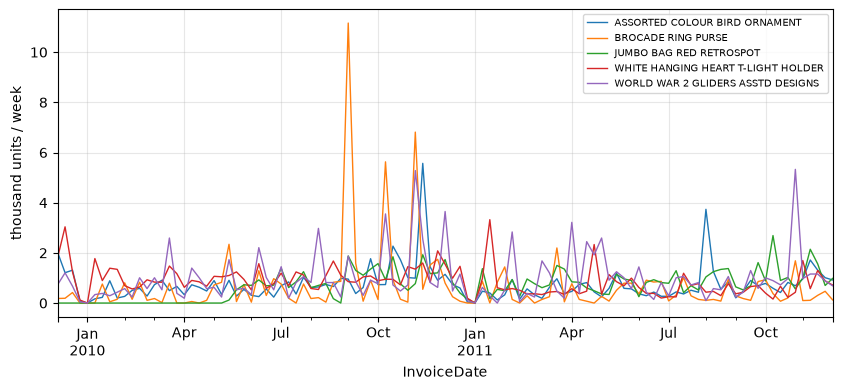

In [9]:
top5 = sales.groupby("Description")["Quantity"].sum().nlargest(5).index
units = (sales[sales["Description"].isin(top5)].set_index("InvoiceDate")
         .groupby("Description")["Quantity"].resample("W").sum().unstack(0).fillna(0))
fig, ax = plt.subplots(figsize=(10, 4))
(units / 1000).plot(ax=ax, linewidth=1); ax.set_ylabel("thousand units / week"); ax.grid(alpha=.3)
ax.legend(fontsize=7); plt.show()

Every product has its own spikes (one big wholesale order), its own season (or none), and long quiet stretches. The industry approach is a **global model**: one gradient-boosting model trained on a stacked table with a row per *product × week*, features such as the product's lags, its category, its price, and the calendar, plus a `product_id` column. It learns "Christmas items surge in October" once, from every Christmas item, instead of separately for each. That is the stretch task in the project.

## Quiz answers

1. Each row is a time step; columns are values known before it (lags, rolling means, calendar); the target is the value at that step.
2. Without `shift(1)`, the 3-day rolling mean on day *t* includes day *t* itself, so the feature contains the answer: leakage.
3. Direct: one model per horizon, or features old enough for the whole horizon; no compounding. Recursive: one-step model, predictions fed back in; fresher information but errors compound.
4. Because a 5-week direct forecast must know every feature for every day in the 5 weeks at the origin; lags shorter than 35 days would not be available.
5. Trees predict averages of training targets in a leaf, so they cannot predict values outside the range seen in training. With `lag_364`, the training rows excluded November 2010, so November 2011 was out of range.

**Next:** [07.P Mini-project: the December stock forecast](../project/)